# Part 2: Language classification with hyperdimensional vectors

This notebook uses 3-grams and random +1/-1 hypervectors to recognize 21 European languages.

In [2]:
import glob
from itertools import islice
import hashlib
import re
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, ConfusionMatrixDisplay

In [3]:
DATA_DIR = "News Wortschatz Corpora Dataset"

languages = {
    "bul": "Bulgarian",
    "ces": "Czech",
    "dan": "Danish",
    "deu": "German",
    "ell": "Greek",
    "eng": "English",
    "est": "Estonian",
    "fin": "Finnish",
    "fra": "French",
    "hun": "Hungarian",
    "ita": "Italian",
    "lav": "Latvian",
    "lit": "Lithuanian",
    "nld": "Dutch",
    "pol": "Polish",
    "por": "Portuguese",
    "ron": "Romanian",
    "slk": "Slovak",
    "slv": "Slovene",
    "spa": "Spanish",
    "swe": "Swedish",
}

labels = list(languages.values())

In [ ]:
def clean_text(text):
    # Keeping letters and replace punctuation/numbers with spaces.
    text = "".join(ch.lower() if ch.isalpha() else " " for ch in text)
    return re.sub(r"\s+", " ", text).strip()


def read_sentences(code):
    path = glob.glob(f"{DATA_DIR}/{code}_news_*/*-sentences.txt")
    if not path:
        raise FileNotFoundError(f"No sentence file found for {code}")

    texts = []
    with open(path[0], "r", encoding="utf-8") as file:
        for line in file:
            if "\t" in line:
                text = line.split("\t", 1)[1]
            else:
                text = re.sub(r"^\d+\s+", "", line)
            text = clean_text(text)
            if text:
                texts.append(text)
    return texts


train_texts, train_labels = [], []
val_texts, val_labels = [], []
test_texts, test_labels = [], []

for code, name in languages.items():
    texts = read_sentences(code)
    random.Random(42).shuffle(texts)
    n_train = int(0.70 * len(texts))
    n_val = int(0.15 * len(texts))

    train_texts.extend(texts[:n_train])
    train_labels.extend([name] * n_train)
    val_texts.extend(texts[n_train:n_train + n_val])
    val_labels.extend([name] * n_val)
    test_texts.extend(texts[n_train + n_val:])
    test_labels.extend([name] * (len(texts) - n_train - n_val))

print(len(train_texts), len(val_texts), len(test_texts))

147000 31500 31500


## 3-gram hypervector encoding

Each trigram receives a deterministic random bipolar vector containing only +1 and -1 values. The vector for a text is the sum of the vectors of all trigrams in that text.

In [5]:
def trigram_vector(trigram, dimension):
    seed = int.from_bytes(hashlib.sha256(trigram.encode("utf-8")).digest()[:8], "little")
    rng = np.random.default_rng(seed)
    vector = rng.integers(0, 2, dimension, dtype=np.int8)
    return vector * 2 - 1


def encode(text, dimension, cache):
    counts = Counter(text[i:i + 3] for i in range(len(text) - 2))
    result = np.zeros(dimension, dtype=np.int32)
    for trigram, count in counts.items():
        if trigram not in cache:
            cache[trigram] = trigram_vector(trigram, dimension)
        result += count * cache[trigram]
    return result

In [6]:
def cosine(query, centroid):
    denominator = np.linalg.norm(query) * np.linalg.norm(centroid)
    return 0.0 if denominator == 0 else np.dot(query, centroid) / denominator


def train_and_test(dimension, train_texts, train_labels, query_texts, query_labels):
    cache = {}
    centroids = {name: np.zeros(dimension, dtype=np.int32) for name in labels}

    # Add text vectors to obtain one centroid per language.
    for text, label in zip(train_texts, train_labels):
        centroids[label] += encode(text, dimension, cache)

    predictions = []
    for text in query_texts:
        query = encode(text, dimension, cache)
        similarities = {
            name: cosine(query, centroid)
            for name, centroid in centroids.items()
        }
        predictions.append(max(similarities, key=similarities.get))

    cm = confusion_matrix(query_labels, predictions, labels=labels)
    accuracy = accuracy_score(query_labels, predictions)
    f1 = f1_score(query_labels, predictions, average="macro")
    return accuracy, f1, cm

d=100: validation accuracy=0.7179, macro-F1=0.7154


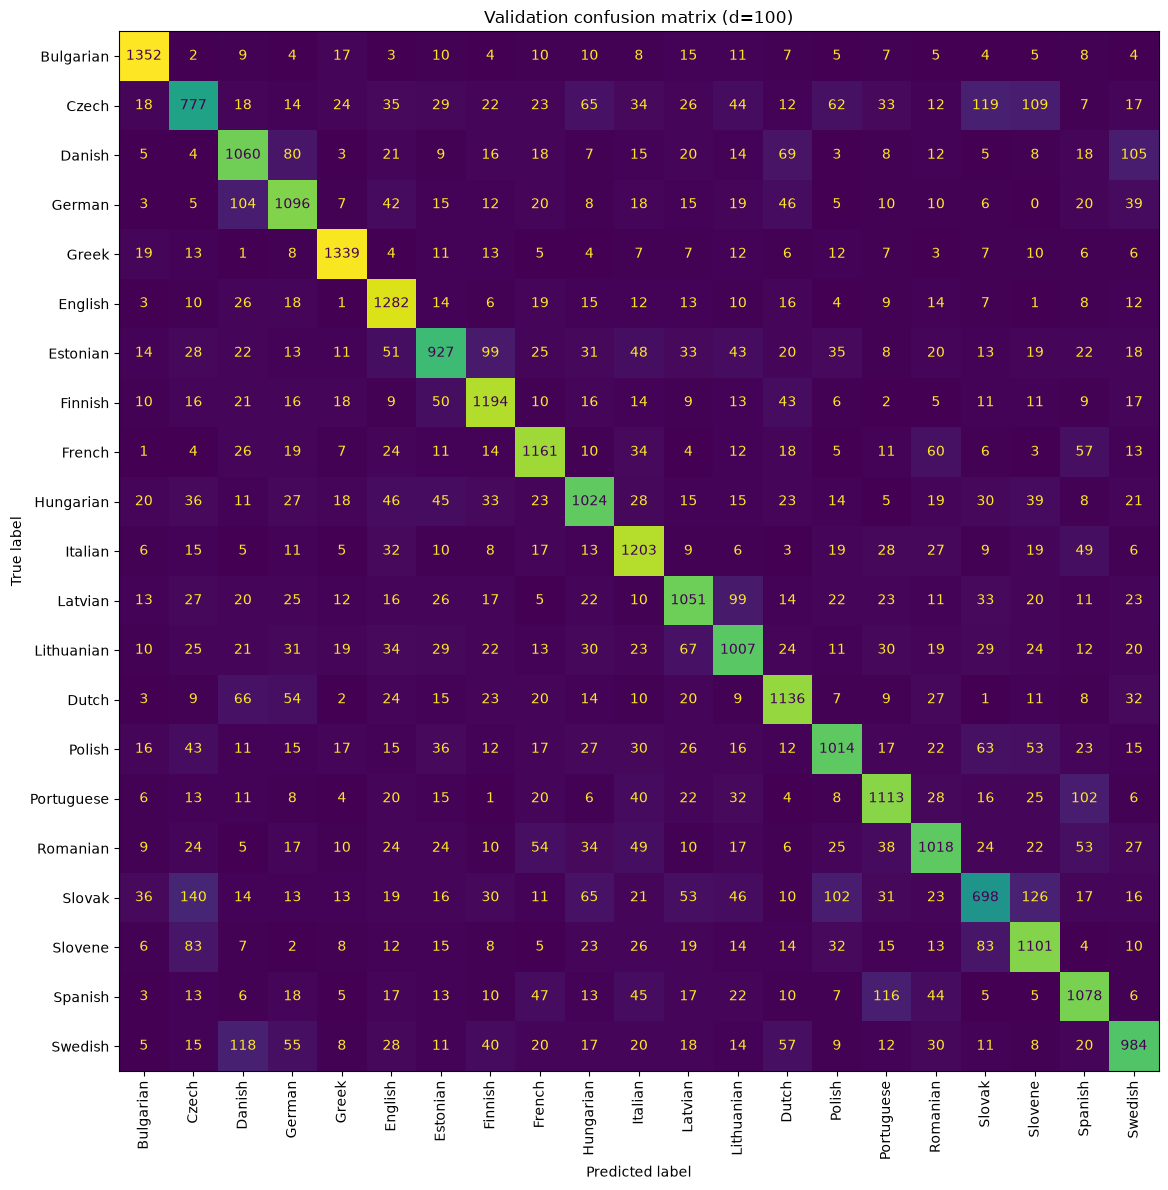

d=1000: validation accuracy=0.9537, macro-F1=0.9536


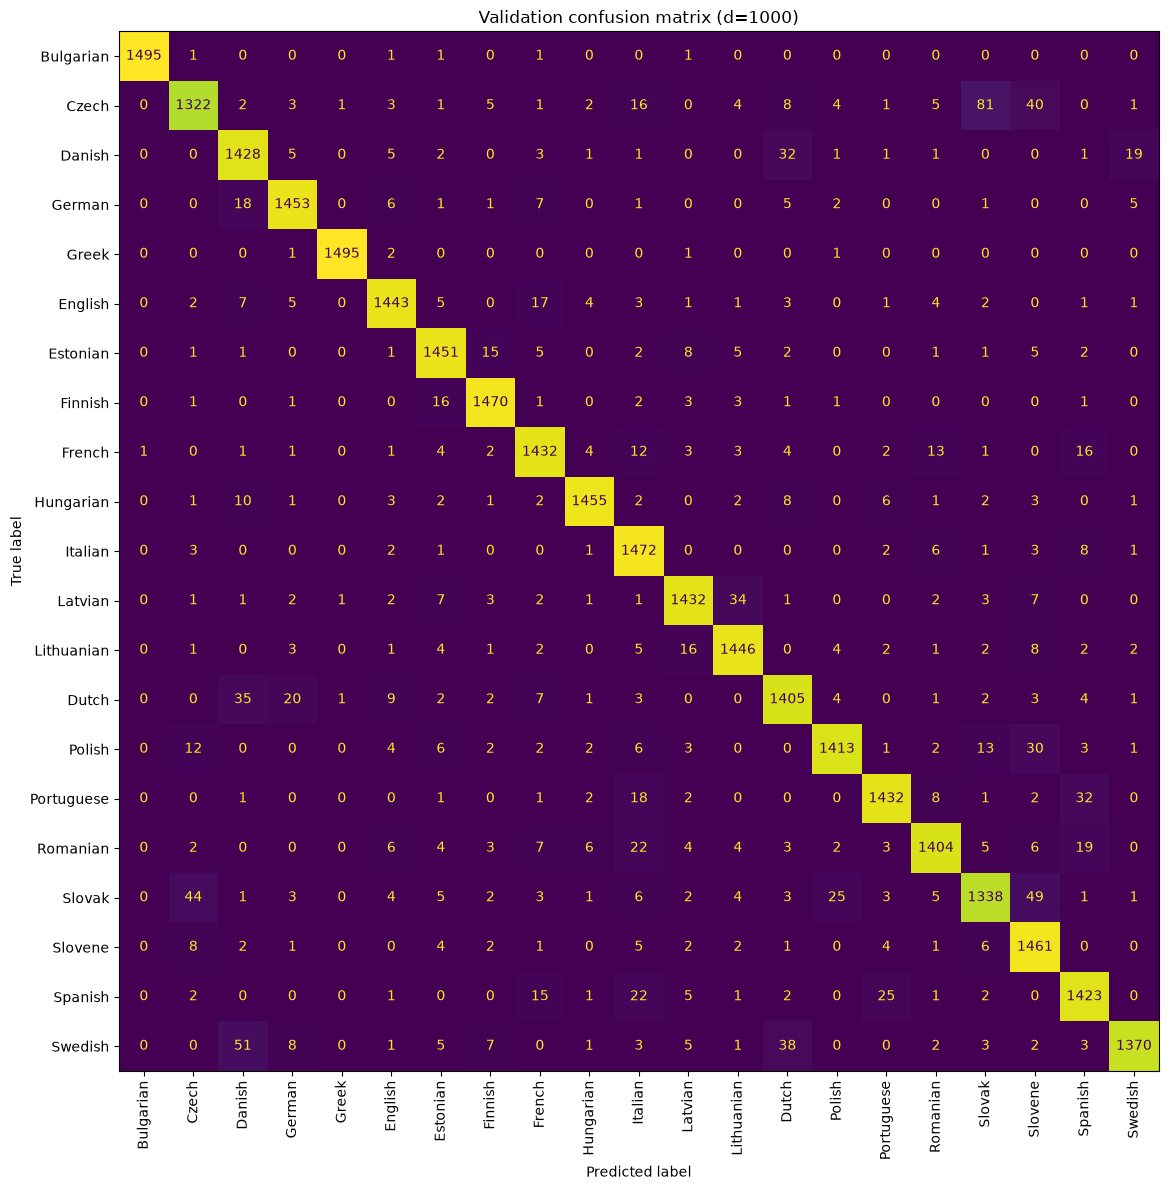

In [7]:
for dimension in (100, 1000):
    accuracy, f1, cm = train_and_test(
        dimension, train_texts, train_labels, val_texts, val_labels
    )
    print(f"d={dimension}: validation accuracy={accuracy:.4f}, macro-F1={f1:.4f}")

    disp = ConfusionMatrixDisplay(cm, display_labels=labels)
    fig, ax = plt.subplots(figsize=(12, 12))
    disp.plot(ax=ax, xticks_rotation=90, colorbar=False)
    ax.set_title(f"Validation confusion matrix (d={dimension})")
    plt.tight_layout()
    plt.show()

d=100: test accuracy=0.7188, macro-F1=0.7160


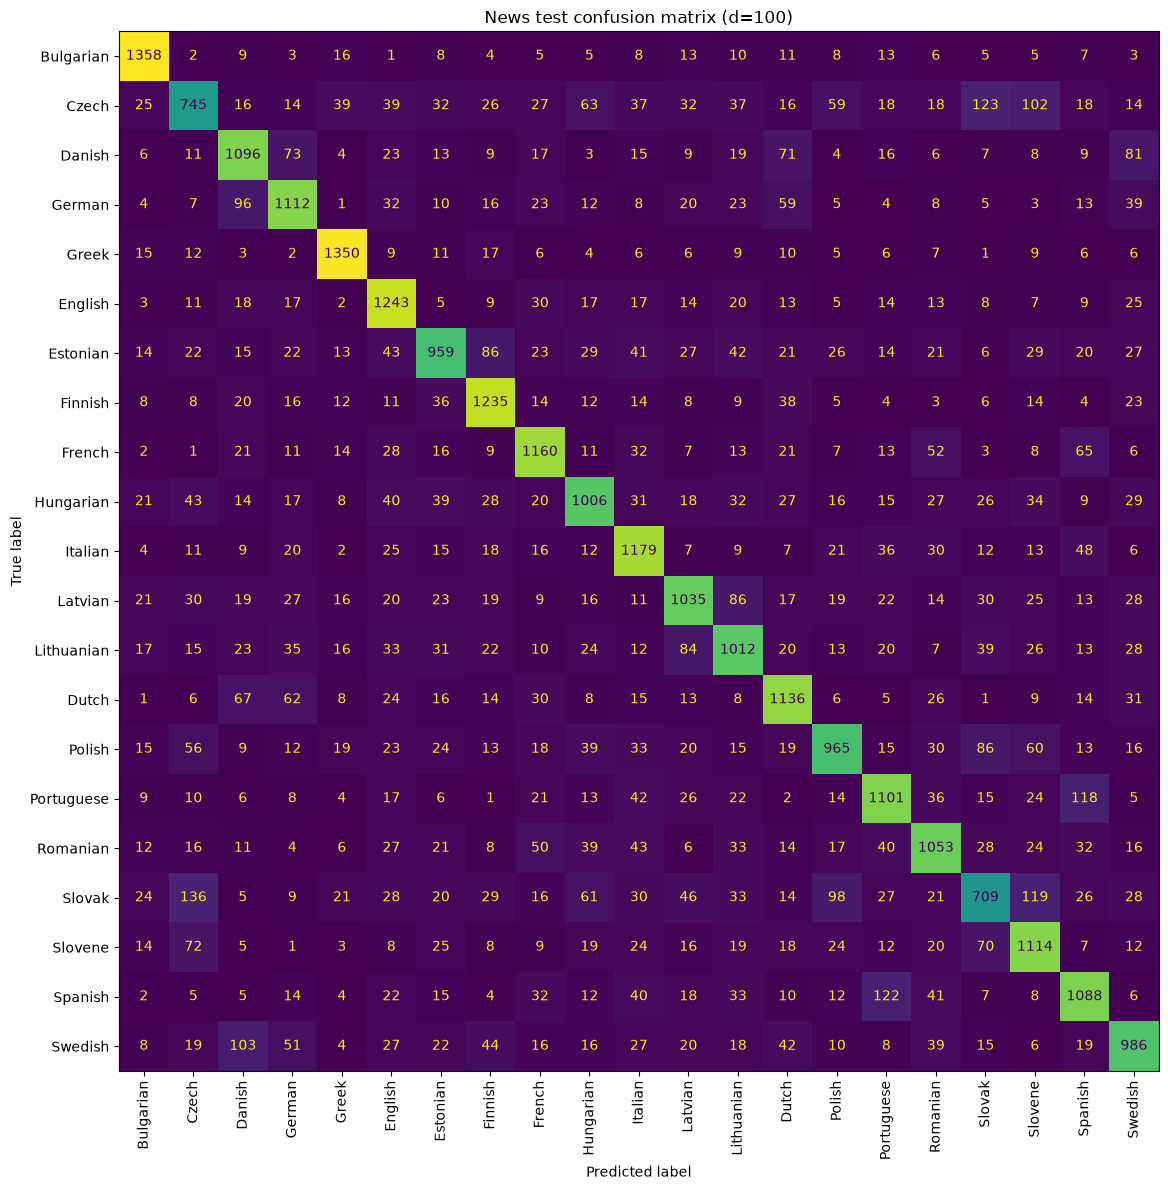

d=1000: test accuracy=0.9520, macro-F1=0.9520


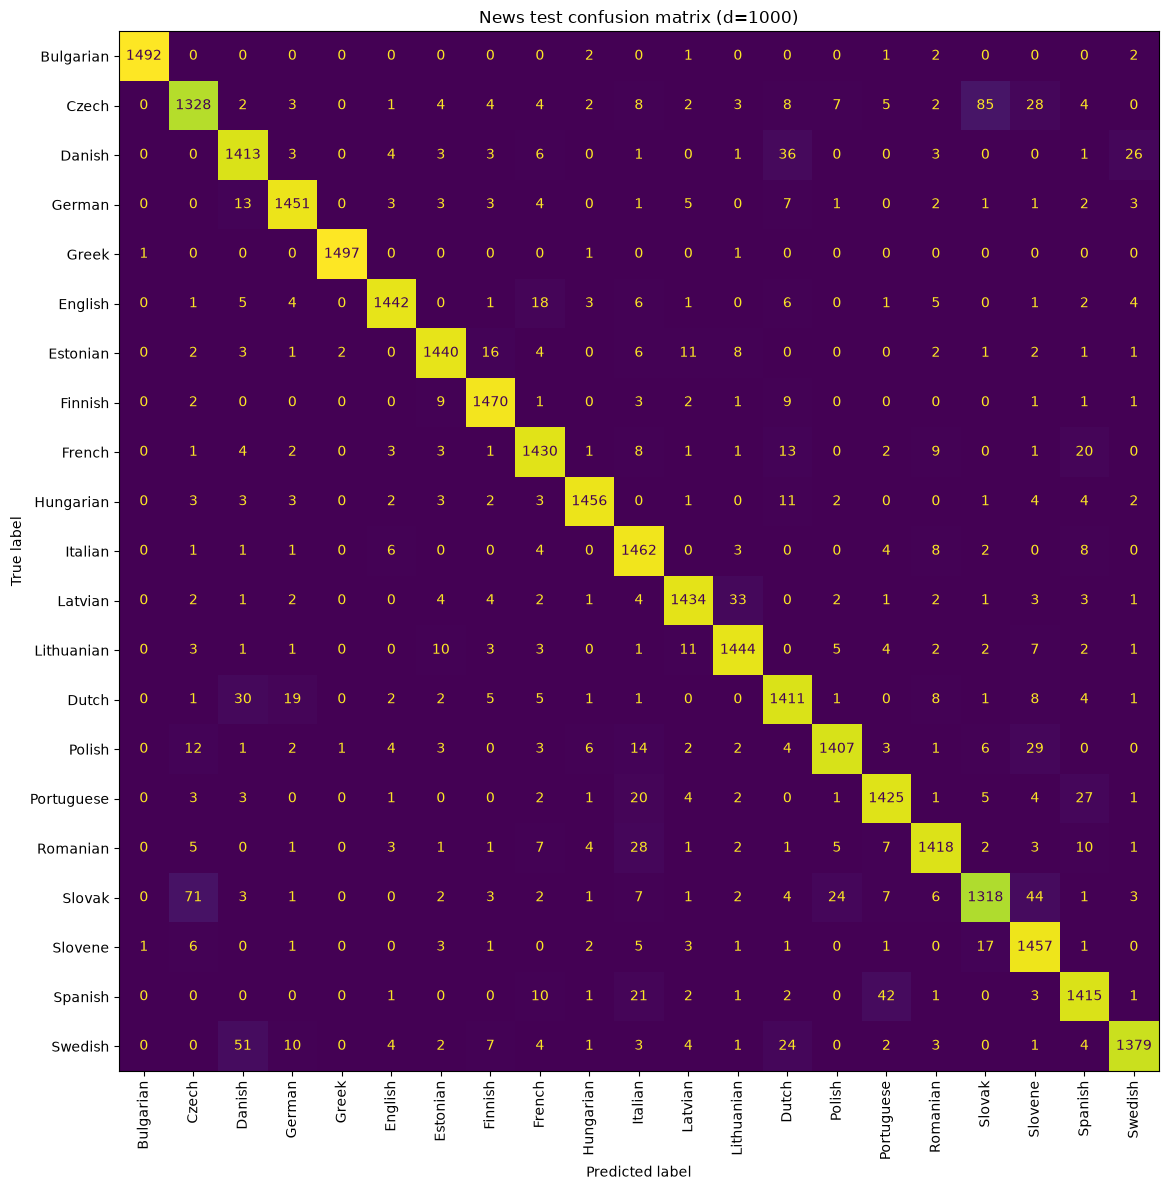

In [8]:
# Final test on sentences from the News Wortschatz test split.
for dimension in (100, 1000):
    accuracy, f1, cm = train_and_test(
        dimension, train_texts, train_labels, test_texts, test_labels
    )
    print(f"d={dimension}: test accuracy={accuracy:.4f}, macro-F1={f1:.4f}")

    disp = ConfusionMatrixDisplay(cm, display_labels=labels)
    fig, ax = plt.subplots(figsize=(12, 12))
    disp.plot(ax=ax, xticks_rotation=90, colorbar=False)
    ax.set_title(f"News test confusion matrix (d={dimension})")
    plt.tight_layout()
    plt.show()

## Euro Parliament final test

Place the extracted Europarl text files in a folder named `Europarl`. This section reads the first 300 lines from each language file and uses the centroids trained on News Wortschatz.

In [9]:
EUROPARL_DIR = "Europarl"


def read_europarl():
    euro_texts, euro_labels = [], []
    for code, name in languages.items():
        files = glob.glob(f"{EUROPARL_DIR}/**/*.{code}.txt", recursive=True)
        if not files:
            files = glob.glob(f"{EUROPARL_DIR}/**/*-{code}.txt", recursive=True)
        if not files:
            continue

        with open(files[0], "r", encoding="utf-8") as file:
            for line in islice(file, 300):
                text = clean_text(line)
                if text:
                    euro_texts.append(text)
                    euro_labels.append(name)
    return euro_texts, euro_labels


euro_texts, euro_labels = read_europarl()
if euro_texts:
    for dimension in (100, 1000):
        accuracy, f1, cm = train_and_test(
            dimension, train_texts, train_labels, euro_texts, euro_labels
        )
        print(f"d={dimension}: Europarl accuracy={accuracy:.4f}, macro-F1={f1:.4f}")
else:
    print("Europarl files are not attached. Add them to the Europarl folder to run the final test.")

Europarl files are not attached. Add them to the Europarl folder to run the final test.


## Conventional representation size

For character trigrams and an alphabet of size A, a conventional one-hot n-gram vector has size A^3. In machine learning, this representation is extremely sparse and can become very large. It requires storing or indexing an enormous number of possible combinations, while many trigrams occur rarely or never in the training data.